In [58]:
import os
import random
import warnings

import matplotlib.pyplot as plt

import torch
import torchvision.models as models
import torchvision.transforms.functional as F

from tqdm import tqdm

from torch.export import export
from torch.utils.data import Subset

from torchvision import datasets, transforms
from torchvision.io import decode_image

from torchmetrics.segmentation import DiceScore, MeanIoU
from torchao.quantization.pt2e.quantize_pt2e import convert_pt2e, prepare_pt2e

from executorch import version
from executorch.runtime import Runtime
from executorch.exir import to_edge_transform_and_lower
from executorch.backends.xnnpack.partition.xnnpack_partitioner import XnnpackPartitioner
from executorch.backends.xnnpack.quantizer.xnnpack_quantizer import XNNPACKQuantizer, get_symmetric_quantization_config


random.seed(0)
warnings.simplefilter("ignore", FutureWarning)
print("Executorch version: ", version.__version__)

Executorch version:  1.1.0


In [59]:
model_constructors = [
    models.segmentation.deeplabv3_resnet50,
    models.segmentation.deeplabv3_resnet101,
    models.segmentation.deeplabv3_mobilenet_v3_large,
    models.segmentation.lraspp_mobilenet_v3_large,
    models.segmentation.fcn_resnet50,
    models.segmentation.fcn_resnet101,
]
model_weights = [
    models.segmentation.DeepLabV3_ResNet50_Weights.DEFAULT,
    models.segmentation.DeepLabV3_ResNet101_Weights.DEFAULT,
    models.segmentation.DeepLabV3_MobileNet_V3_Large_Weights.DEFAULT,
    models.segmentation.LRASPP_MobileNet_V3_Large_Weights.DEFAULT,
    models.segmentation.FCN_ResNet50_Weights.DEFAULT,
    models.segmentation.FCN_ResNet101_Weights.DEFAULT,
]

In [ ]:
# Resize size used for semantic segmentation models in torchvision, defined as
# `resize_size` parameter in `transforms` field of the `WeightsEnum` classes:
# - https://docs.pytorch.org/vision/main/_modules/torchvision/models/segmentation/deeplabv3.html#DeepLabV3_MobileNet_V3_Large_Weights
# - https://docs.pytorch.org/vision/main/_modules/torchvision/models/segmentation/deeplabv3.html#DeepLabV3_ResNet101_Weights
# - https://docs.pytorch.org/vision/main/_modules/torchvision/models/segmentation/deeplabv3.html#DeepLabV3_ResNet50_Weights
# - https://docs.pytorch.org/vision/main/_modules/torchvision/models/segmentation/fcn.html#FCN_ResNet101_Weights
# - https://docs.pytorch.org/vision/main/_modules/torchvision/models/segmentation/fcn.html#FCN_ResNet50_Weights
# - https://docs.pytorch.org/vision/main/_modules/torchvision/models/segmentation/lraspp.html#LRASPP_MobileNet_V3_Large_Weights
RESIZE_SIZE = [520, 520]

# Directory to store the exported .pte files
EXPORT_DIR = "exports"

# Suffix for odels
SUFFIX = "_xnnpack_int8"

# Paths to the exported .pte files
MODEL_PATH: dict[str, str] = {}

# ImageNet mean and std for normalization
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


def preprocess(img: torch.Tensor):
    """
    Based on the definition of the `transforms` field in the `WeightsEnum`
    classes for our models (which is the same for every listed model that we
    export in this notebook and defined in `SemanticSegmentation` class here:
    https://github.com/pytorch/vision/blob/main/torchvision/transforms/_presets.py),
    except that we resize to the fixed size of 520x520 instead of resizing the
    image such that the shorter edge is 520 pixels and the longer edge is
    rescaled proportionally to the original aspect ratio.
    """
    img = F.resize(img, RESIZE_SIZE, interpolation=F.InterpolationMode.BILINEAR, antialias=True)
    img = F.convert_image_dtype(img, torch.float)
    img = F.normalize(img, mean=IMAGENET_MEAN, std=IMAGENET_STD)
    return img

In [ ]:
print("Exporting models...")

# We use a common dataset of images for calibration of activation ranges.
#
# NOTE: There is some problem with getting the VOCSegmentation dataset to
# download in torchvision (https://github.com/pytorch/vision/issues/9269). You
# can download it from a mirror using the following commands:
# ```
# mkdir -p datasets/VOCSegmentation
# cd datasets/VOCSegmentation
# curl https://dataset.bj.bcebos.com/voc/VOCtrainval_11-May-2012.tar
# ```
#
calibration_dataset = datasets.VOCSegmentation(root="datasets/VOCSegmentation", year="2012", image_set="train")
calibration_size = 100
calibration_imgs = random.sample(calibration_dataset.images, k=calibration_size)

for constructor, weights in zip(model_constructors, model_weights):
    model = constructor(weights=weights).eval()
    inputs = (torch.randn(1, 3, *RESIZE_SIZE),)

    # NOTE: Quantization pipeline is based on the ExecuTorch example for xnnpack
    # backend:
    # https://docs.pytorch.org/executorch/1.1/backends/xnnpack/xnnpack-quantization.html

    # Prepare quantizer
    # -----------------
    quantizer = XNNPACKQuantizer()
    quantizer.set_global(get_symmetric_quantization_config(is_per_channel=True))

    # Prepare model for PTQ
    # ---------------------
    training_ep = export(model, inputs).module()
    prepared_model = prepare_pt2e(training_ep, quantizer)

    # Calibrate activation ranges
    # ---------------------------
    for img in tqdm(calibration_imgs, desc="Calibrating"):
        img = decode_image(img).unsqueeze(0)
        img = preprocess(img)
        prepared_model(img)

    # Export quantized model
    # ----------------------
    quantized_model = convert_pt2e(prepared_model)

    program = to_edge_transform_and_lower(export(quantized_model, inputs), partitioner=[XnnpackPartitioner()])
    program = program.to_executorch()

    with open(path := f"{EXPORT_DIR}/{constructor.__name__}{SUFFIX}.pte", "wb") as f:
        MODEL_PATH[constructor.__name__] = path
        f.write(program.buffer)

    print(f"Exported {path}\n")

Exporting models...


Calibrating: 100%|██████████| 100/100 [01:00<00:00,  1.65it/s]


Exported exports/deeplabv3_resnet50_xnnpack_int8.pte



Calibrating: 100%|██████████| 100/100 [01:48<00:00,  1.08s/it]


Exported exports/deeplabv3_resnet101_xnnpack_int8.pte



Calibrating: 100%|██████████| 100/100 [00:39<00:00,  2.50it/s]


... (3 outputs left out)

Calibrating: 100%|██████████| 100/100 [00:50<00:00,  1.98it/s]


Exported exports/fcn_resnet50_xnnpack_int8.pte



Calibrating: 100%|██████████| 100/100 [01:36<00:00,  1.04it/s]


Exported exports/fcn_resnet101_xnnpack_int8.pte



Visual inspection...


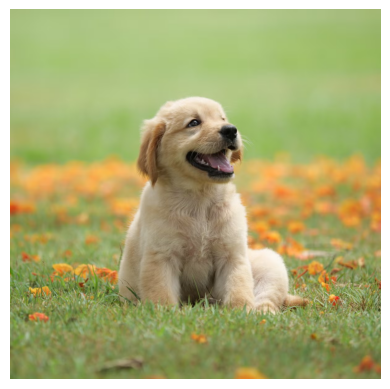

[program.cpp:154] InternalConsistency verification requested but not available


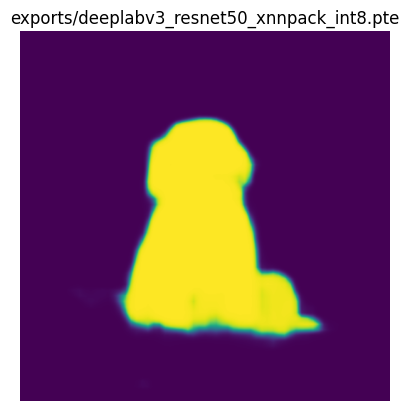

[program.cpp:154] InternalConsistency verification requested but not available


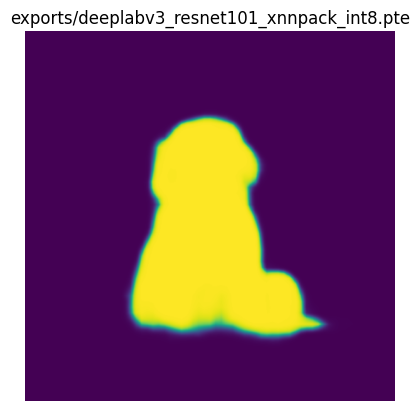

[program.cpp:154] InternalConsistency verification requested but not available


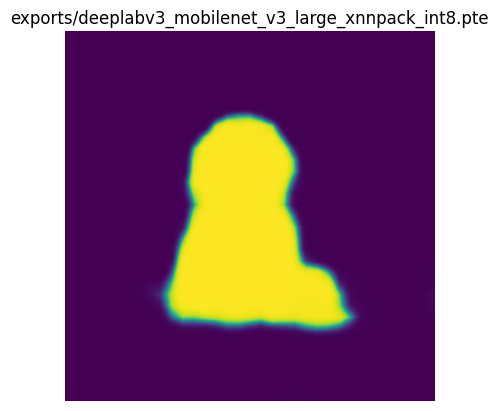

[program.cpp:154] InternalConsistency verification requested but not available


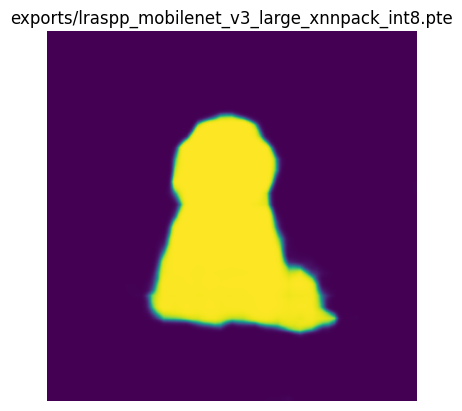

[program.cpp:154] InternalConsistency verification requested but not available


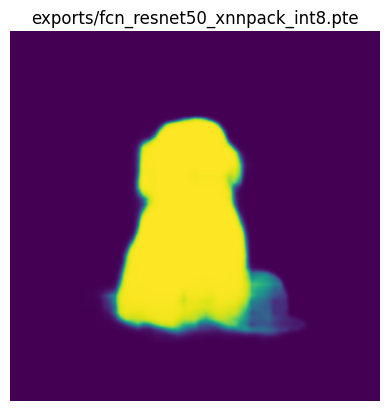

[program.cpp:154] InternalConsistency verification requested but not available


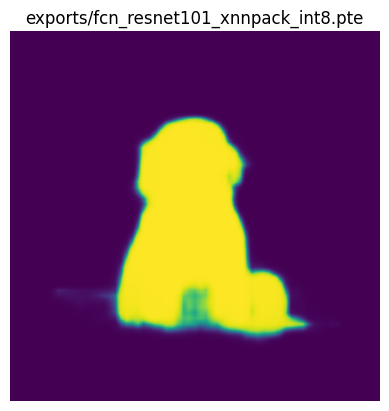

In [ ]:
print("Visual inspection...")

img = decode_image("assets/dog.png")
plt.imshow(F.to_pil_image(img))
plt.axis("off")
plt.show()

for constructor in model_constructors:
    img = decode_image("assets/dog.png").unsqueeze(0)
    img = preprocess(img)

    path = MODEL_PATH[constructor.__name__]
    runtime = Runtime.get()
    program = runtime.load_program(path)
    output, *_ = program.load_method("forward").execute([img])  # type: ignore

    normalized_masks = output.softmax(dim=1)
    class_to_idx = {cls: idx for (idx, cls) in enumerate(weights.meta["categories"])}
    mask = normalized_masks[0, class_to_idx["dog"], ...]

    plt.imshow(mask.numpy(), vmin=0, vmax=1)
    plt.title(path)
    plt.axis("off")
    plt.show()

In [ ]:
target_transform = transforms.Compose([transforms.Resize((520, 520)), transforms.PILToTensor()])
transform = transforms.Compose(
    [
        transforms.Resize((520, 520)),
        transforms.ToTensor(),
        transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ]
)
dataset = datasets.VOCSegmentation(
    root="datasets/VOCSegmentation",
    year="2012",
    image_set="val",
    transform=transform,
    target_transform=target_transform,
)
indices = random.sample(range(len(dataset)), k=100)
dataset = Subset(dataset, indices=indices)
num_classes = 21  # VOC has 20 objects + 1 background

for constructor, weights in zip(model_constructors, model_weights):
    print(constructor.__name__.upper())

    # --- PyTorch Eager Reference ---

    model = constructor(weights=weights).eval()

    dice = DiceScore(num_classes=num_classes, input_format="mixed", average="micro")
    miou = MeanIoU(num_classes=num_classes, input_format="mixed")

    for img, mask in tqdm(dataset, desc="PyTorch Reference Model"):
        img = img.unsqueeze(0)
        mask[mask == 255] = 0
        mask = mask.to(torch.long)
        with torch.inference_mode():
            preds = model(img)["out"]
        dice.update(preds, mask)
        miou.update(preds, mask)

    print(
        "----------------------------------\n"
        f"Reference Mean IoU:   {miou.compute():.4f}\n"
        f"Reference Dice Score: {dice.compute():.4f}\n"
        "----------------------------------"
    )

    # --- ExecuTorch Inference ---

    path = MODEL_PATH[constructor.__name__]
    runtime = Runtime.get()
    program = runtime.load_program(path)

    dice = DiceScore(num_classes=num_classes, input_format="mixed")
    miou = MeanIoU(num_classes=num_classes, input_format="mixed")

    for img, mask in tqdm(dataset, desc="ExecuTorch Model"):
        img = img.unsqueeze(0)
        mask[mask == 255] = 0
        mask = mask.to(torch.long)
        preds, *_ = program.load_method("forward").execute([img])  # type: ignore
        dice.update(preds, mask)
        miou.update(preds, mask)

    print(
        f"{path} Mean IoU:   {miou.compute():.4f}\n"
        f"{path} Dice Score: {dice.compute():.4f}\n"
        f"{path} Size:       {os.path.getsize(path) / 1024 / 1024:.2f}MB\n"
        "----------------------------------\n"
    )

DEEPLABV3_RESNET50


PyTorch Reference Model: 100%|██████████| 100/100 [00:51<00:00,  1.93it/s]
[program.cpp:154] InternalConsistency verification requested but not available


----------------------------------
Reference Mean IoU:   0.7217
Reference Dice Score: 0.9232
----------------------------------


ExecuTorch Model: 100%|██████████| 100/100 [00:38<00:00,  2.60it/s]


exports/deeplabv3_resnet50_xnnpack_int8.pte Mean IoU:   0.7227
exports/deeplabv3_resnet50_xnnpack_int8.pte Dice Score: 0.9239
exports/deeplabv3_resnet50_xnnpack_int8.pte Size:       40.42MB
----------------------------------

DEEPLABV3_RESNET101


PyTorch Reference Model: 100%|██████████| 100/100 [01:12<00:00,  1.37it/s]
[program.cpp:154] InternalConsistency verification requested but not available


... (15 outputs left out)

PyTorch Reference Model: 100%|██████████| 100/100 [01:07<00:00,  1.49it/s]
[program.cpp:154] InternalConsistency verification requested but not available


----------------------------------
Reference Mean IoU:   0.6167
Reference Dice Score: 0.9229
----------------------------------


ExecuTorch Model: 100%|██████████| 100/100 [00:47<00:00,  2.10it/s]

exports/fcn_resnet101_xnnpack_int8.pte Mean IoU:   0.6186
exports/fcn_resnet101_xnnpack_int8.pte Dice Score: 0.9225
exports/fcn_resnet101_xnnpack_int8.pte Size:       52.46MB
----------------------------------

